# 01 — Land, river, and sea-ice initial conditions for RTENSO2026: year selection

No model restarts exist for 2026, so the ELM (land), MOSART (river), and
MPAS-Seaice initial conditions come from one year of the BruteForce archive,
used unchanged (averaging restarts would break the consistency of snow layers,
ice categories, and phenology). Two branches choose the year:

| Branch | Year selected | Target |
| --- | --- | --- |
| `clim` | closest to the climatology | candidate-year mean |
| `obs` | closest to the observed state | ERA5 anomaly on the target date |

The 2015 dates are done the same way, with 2015 excluded from the candidates,
to test hindcast sensitivity against the actual 2015 restarts. Similarity checks
and spatial plots comparing the `clim` and `obs` choices against the actual 2015
restarts are in `02_evaluate_ic_metrics.ipynb`, `03_plot_mpassi_ic_mosaic.ipynb`, and `04_plot_elm_ic_mosaic.ipynb`.

## Distance metric

For key field $f$ (section 1), candidate-year values are converted to
standardized anomalies $z_{y,i}=(x_{y,i}-\bar x_i)/S$, where
$S^2=\sum_i w_i s_i^2/\sum_i w_i$ is the area-weighted mean interannual
variance over the candidate years. The distance of year $y$ from a target
$t$ is

$$d_f(y)=\sqrt{\frac{\sum_i w_i\,(z_{y,i}-t_i)^2}{\sum_i w_i}}$$

- `clim`: $t=0$. $d_f$ is the RMS anomaly relative to the RMS spread; its mean
  square over the candidate years is 1, so $d_f<1$ is closer than a typical year.
- `obs`: $t$ is the ERA5 standardized anomaly on the target date,
  $(o_T-\bar o)/S_\mathrm{obs}$, with the ERA5 mean and spread over the same
  candidate years and date. Comparing anomalies cancels model-ERA5 biases and
  unit or layer-depth differences. Only fields with an ERA5 counterpart are
  used.

The river (MOSART) is not in the distance (its storage is driven by land
runoff); its restart always comes from the land year. The two soil-water
fields cover disjoint layers (1-3 and 4+), so no layer is counted twice.

Component distance $D_c=\sqrt{\operatorname{mean}_{f\in c} d_f^2}$; joint
distance $D=\sqrt{\sum_c a_c D_c^2/\sum_c a_c}$ with component weights $a_c$
(default 1). `MODE = "joint"` takes the year with the smallest $D$ for all
components (one coupled state); `"per_component"` takes each component's
smallest $D_c$.

The BruteForce archive is read-only here. Code: `util/clim_restart.py`.

For the 2015 sensitivity check and native-grid spatial similarity comparisons against the actual 2015 restarts, see:
- `02_evaluate_ic_metrics.ipynb` — Distance/rank checks, field-level similarity tables (`d_box`, `r_box`, `d_grid`, `r_grid`, `RMSE`, `bias`), global integrated summaries, and $30^\circ \times 60^\circ$ box anomaly maps
- `03_plot_mpassi_ic_mosaic.ipynb` — MPAS-Seaice native unstructured mesh comparisons via `mosaic`
- `04_plot_elm_ic_mosaic.ipynb` — ELM native `grid1d` land mesh comparisons via `mosaic`

In [1]:
from pathlib import Path
import importlib
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import netCDF4 as nc

SEARCH_ROOTS = (Path.cwd().resolve(), *Path.cwd().resolve().parents)
HELPER_RELATIVE_PATHS = (
    Path("util"),
    Path("rtenso2026/util"),
    Path("ensemble_init/rtenso2026/util"),
    Path("e3sm_s2d_proc/ensemble_init/rtenso2026/util"),
)
HELPER_DIR = next(
    (
        root / relative_path
        for root in SEARCH_ROOTS
        for relative_path in HELPER_RELATIVE_PATHS
        if (root / relative_path / "clim_restart.py").is_file()
    ),
    None,
)
if HELPER_DIR is None:
    raise FileNotFoundError("Could not find util/clim_restart.py from the notebook directory.")
if str(HELPER_DIR) not in sys.path:
    sys.path.insert(0, str(HELPER_DIR))

import clim_restart
clim_restart = importlib.reload(clim_restart)
from clim_restart import (
    compute_distances,
    distance_to_model_year,
    era5_available,
    make_plan,
    metric_table,
    select_years,
    source_file,
    summarize_restart,
    write_selected_restarts,
)

warnings.filterwarnings("ignore", category=RuntimeWarning)

## Configuration

In [ ]:
# Model initial-condition archive (BruteForce restarts, opened read-only).
SRC_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/BruteForce")
SRC_PREFIX = "20251024_s2d_spinup"

# Observation setup for land (elm) and sea ice (mpassi) in the 'obs' branch.
# Leave as None (or per-component {"elm": None, "mpassi": None}) to automatically
# use the default NERSC ERA5 setup (/global/cfs/projectdirs/m3522/cmip6/ERA5/e5.oper.an.sfc
# and default ERA5 variables: sd, swvl1, swvl2-4, stl1 for elm; ci for mpassi).
# To override, specify a Path or dict of Paths for OBS_ROOT, and/or custom
# field mappings for OBS_FIELDS.

# Default observation setup (use None to automatically select the default NERSC ERA5 setup)
#OBS_ROOT = {"elm": None, "mpassi": None}
#OBS_FIELDS = {"elm": None, "mpassi": None}
#OBS_ROOT = {
#    "elm": Path("/global/cfs/projectdirs/m3522/cmip6/ERA5/e5.oper.an.sfc"), 
#    "mpassi": Path("/global/cfs/projectdirs/m3522/cmip6/ERA5/e5.oper.an.sfc")
#}
#OBS_FIELDS = {
#    "elm": ["sd", "swvl1", "swvl2-4", "stl1"], 
#    "mpassi": ["ci"]
#}

OBS_ROOT = {
    "elm": Path("/global/cfs/projectdirs/m3522/cmip6/ERA5/e5.oper.an.sfc"), 
    "mpassi": Path("/global/cfs/projectdirs/m3522/cmip6/ERA5/e5.oper.an.sfc")
}
OBS_FIELDS = {
    "elm": ["sd", "swvl1", "swvl2-4", "stl1"], 
    "mpassi": ["ci"]
}

# Fixed RTENSO2026 output location: OUT_ROOT/YYYYMMDD/<branch>/<prefix>.<stream>.<date>.nc
OUT_ROOT = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions")

OUT_PREFIX = "20251024_s2d_spinup"   # matches my_refcase2 in the hindcast driver

BRANCHES = ["clim", "obs"]

COMPONENTS = ["elm", "mosart", "mpassi"]

TEST_DATES = ["2015-02-01", "2015-05-01", "2015-08-01", "2015-11-01"]

HINDCAST_DATES = ["2026-02-01", "2026-05-01", "2026-08-01", "2026-11-01"]

TARGET_DATES = TEST_DATES + HINDCAST_DATES

# Candidate years. None uses every available year (1980-2018).
FIRST_YEAR = None # None is 1980 
LAST_YEAR = None  # None is 2018

EXCLUDE_YEARS = []
EXCLUDE_TARGET_YEAR = True          # 2015 cannot select itself

# Compare area-weighted means over (dlat, dlon)-degree boxes; None = model points.
# 30 x 60 matched the actual 2015 state best (README, "Choice of box size").
BOX = (30, 60)

# modes: use joint for all components or per_component for individual components
MODE = "joint"  # or "per_component"

# weight for components 
# e.g. {"mpassi": 2.0}; default 1 each 
COMPONENT_WEIGHTS = {
    "mpassi": 1.0,
    "elm": 1.0
}

# Model and observation key fields are cached under the output root.
CACHE_DIR = OUT_ROOT / "cache"

WRITE_OUTPUT = False                # True copies the selected restarts to OUT_ROOT
OVERWRITE = False

## 1. Key fields and their ERA5 counterparts

In [3]:
display(metric_table(OBS_FIELDS))

,component,field,model definition,"domain, weight",ERA5 (obs branch)
0,mpassi,NH ice concentration,sum of iceAreaCategory,"lat > 0, areaCell",ci
1,mpassi,SH ice concentration,sum of iceAreaCategory,"lat < 0, areaCell",ci
2,mpassi,NH ice thickness,sum of iceVolumeCategory (m),"lat > 0, areaCell",--
3,mpassi,SH ice thickness,sum of iceVolumeCategory (m),"lat < 0, areaCell",--
4,mpassi,NH snow on ice,sum of snowVolumeCategory (m),"lat > 0, areaCell",--
5,mpassi,SH snow on ice,sum of snowVolumeCategory (m),"lat < 0, areaCell",--
6,elm,snow water equivalent,H2OSNO (mm),"active columns, cols1d_wtxy*cos(lat)",sd
7,elm,surface soil water,"H2OSOI_LIQ + H2OSOI_ICE, soil layers 1-3 (kg m-2)","active columns, cols1d_wtxy*cos(lat)",swvl1
8,elm,subsurface soil water,"H2OSOI_LIQ + H2OSOI_ICE, soil layers 4 and bel...","active columns, cols1d_wtxy*cos(lat)",swvl2-4
9,elm,surface soil temperature,"T_SOISNO, soil layer 1 (K)","active columns, cols1d_wtxy*cos(lat)",stl1


## 2. Distances and selection

The first run for a calendar month reads the model key fields (about 3.5
minutes) and, for `obs`, the ERA5 fields (one 00Z slice per variable and year);
both are cached. `obs` is skipped for dates ERA5 does not cover yet.

In [4]:
plans = {}
distances = {}
selections = {}

for branch in BRANCHES:
    for date in TARGET_DATES:
        if branch == "obs" and not era5_available(
            date, obs_root=OBS_ROOT, obs_fields=OBS_FIELDS, components=COMPONENTS
        ):
            print(f"skip {branch} {date}: ERA5 not available yet")
            continue
        plan = make_plan(
            date, branch, components=COMPONENTS,
            src_root=SRC_ROOT, src_prefix=SRC_PREFIX,
            out_root=OUT_ROOT, out_prefix=OUT_PREFIX,
            obs_root=OBS_ROOT, obs_fields=OBS_FIELDS,
            first_year=FIRST_YEAR, last_year=LAST_YEAR,
            exclude_years=EXCLUDE_YEARS, exclude_target_year=EXCLUDE_TARGET_YEAR,
        )
        table = compute_distances(plan, box=BOX, component_weights=COMPONENT_WEIGHTS, cache_dir=CACHE_DIR)
        key = (branch, date)
        plans[key], distances[key] = plan, table
        selections[key] = select_years(table, COMPONENTS, MODE)

summary = []
for (branch, date), table in distances.items():
    ranked = table["joint"].sort_values()
    row = {"branch": branch, "target_date": date, "n_candidates": len(table)}
    row.update({f"{c} year": y for c, y in selections[(branch, date)].items()})
    row.update({"best D": ranked.iloc[0], "2nd year": ranked.index[1], "2nd D": ranked.iloc[1],
                "3rd year": ranked.index[2], "3rd D": ranked.iloc[2]})
    summary.append(row)
summary = pd.DataFrame(summary)
display(summary.round(3))

skip obs 2026-08-01: ERA5 not available yet
skip obs 2026-11-01: ERA5 not available yet


,branch,target_date,n_candidates,elm year,mosart year,mpassi year,best D,2nd year,2nd D,3rd year,3rd D
0,clim,2015-02-01,38,1995,1995,1995,0.731,2000,0.769,2002,0.780
1,clim,2015-05-01,38,1995,1995,1995,0.746,1996,0.755,2004,0.760
2,clim,2015-08-01,38,1988,1988,1988,0.773,1997,0.809,2008,0.815
3,clim,2015-11-01,38,2000,2000,2000,0.741,2001,0.778,2008,0.791
4,clim,2026-02-01,39,1995,1995,1995,0.734,2000,0.770,2002,0.774
5,clim,2026-05-01,39,1995,1995,1995,0.744,2004,0.755,1996,0.758
6,clim,2026-08-01,39,1988,1988,1988,0.780,1997,0.803,2008,0.804
7,clim,2026-11-01,39,2000,2000,2000,0.751,2001,0.788,2008,0.791
8,obs,2015-02-01,38,1990,1990,1990,1.204,1984,1.263,2014,1.336
9,obs,2015-05-01,38,2014,2014,2014,1.170,2012,1.215,2008,1.268


In [5]:
# Ten closest years for each branch and date (field, component, and joint distances).
for (branch, date), table in distances.items():
    print(f"{branch} {date}")
    display(table.sort_values("joint").head(10).round(3))

clim 2015-02-01


,elm: snow water equivalent,elm: surface soil water,elm: subsurface soil water,elm: surface soil temperature,elm,mpassi: NH ice concentration,mpassi: SH ice concentration,mpassi: NH ice thickness,mpassi: SH ice thickness,mpassi: NH snow on ice,mpassi: SH snow on ice,mpassi,joint
year,,,,,,,,,,,,,
1995,0.604,0.967,0.914,0.838,0.842,0.460,0.493,0.507,0.558,0.970,0.435,0.599,0.731
2000,0.521,0.733,0.873,0.893,0.769,0.731,1.140,0.528,0.851,0.476,0.689,0.768,0.769
2002,0.688,0.619,0.639,0.836,0.701,0.462,1.051,0.294,1.009,0.666,1.218,0.851,0.780
2004,0.797,0.966,0.982,0.697,0.868,0.847,0.591,0.828,0.705,0.514,0.525,0.682,0.781
1989,0.948,0.675,0.866,0.886,0.850,0.954,0.688,0.979,0.509,0.716,0.446,0.743,0.798
2005,0.709,0.670,0.862,0.938,0.802,1.035,0.976,0.401,0.939,0.886,0.376,0.815,0.809
2009,0.805,0.897,1.093,0.989,0.952,0.763,0.873,0.725,0.475,0.642,0.658,0.700,0.836
1994,0.547,1.072,0.703,0.886,0.826,0.763,0.796,0.718,0.578,1.219,0.919,0.856,0.841
2010,0.968,0.844,0.800,1.123,0.942,0.727,0.746,0.626,0.747,0.775,0.725,0.726,0.841


clim 2015-05-01


,elm: snow water equivalent,elm: surface soil water,elm: subsurface soil water,elm: surface soil temperature,elm,mpassi: NH ice concentration,mpassi: SH ice concentration,mpassi: NH ice thickness,mpassi: SH ice thickness,mpassi: NH snow on ice,mpassi: SH snow on ice,mpassi,joint
year,,,,,,,,,,,,,
1995,0.677,1.023,0.685,1.039,0.874,0.841,0.397,0.683,0.460,0.712,0.239,0.592,0.746
1996,0.901,0.734,0.780,0.823,0.812,0.757,0.946,0.587,0.755,0.559,0.446,0.695,0.755
2004,0.702,1.059,0.700,1.015,0.885,0.555,0.684,0.411,0.570,0.715,0.664,0.609,0.760
1994,0.715,1.020,0.724,0.822,0.829,0.612,0.798,0.510,0.823,0.745,1.020,0.768,0.799
2002,0.915,0.812,0.853,0.915,0.875,0.500,1.015,0.220,0.511,0.672,1.093,0.735,0.808
2009,0.717,0.955,1.069,0.657,0.866,0.609,1.184,0.657,0.758,0.919,0.943,0.867,0.867
1991,0.625,0.802,0.688,0.933,0.771,0.648,0.759,0.718,1.613,0.526,1.039,0.955,0.868
1993,1.129,1.038,0.871,0.728,0.954,0.872,0.736,0.695,1.017,0.704,0.547,0.776,0.870
1988,0.498,1.211,0.988,0.860,0.926,1.111,0.544,0.947,0.751,0.857,0.720,0.841,0.884


clim 2015-08-01


...

,elm: snow water equivalent,elm: surface soil water,elm: subsurface soil water,elm: surface soil temperature,elm,mpassi: NH ice concentration,mpassi: SH ice concentration,mpassi,joint
year,,,,,,,,,
1995,0.964,1.508,1.608,1.395,1.391,0.934,0.783,0.862,1.157
2013,1.245,1.183,1.682,1.041,1.310,0.802,1.148,0.991,1.161
2017,0.979,1.296,1.576,1.194,1.279,0.916,1.135,1.032,1.162
1997,1.084,1.534,2.009,1.093,1.480,0.766,0.845,0.807,1.192
2014,1.078,1.264,1.685,1.046,1.293,0.974,1.181,1.083,1.193
1980,1.463,1.203,1.536,1.237,1.367,1.093,0.888,0.996,1.196
2004,1.304,1.084,1.748,1.222,1.362,0.938,1.144,1.046,1.214
1994,1.061,1.399,1.602,1.521,1.411,1.299,0.683,1.037,1.238
1991,1.001,1.325,1.718,1.595,1.437,0.931,1.135,1.038,1.253


obs 2026-02-01


,elm: snow water equivalent,elm: surface soil water,elm: subsurface soil water,elm: surface soil temperature,elm,mpassi: NH ice concentration,mpassi: SH ice concentration,mpassi,joint
year,,,,,,,,,
2010,0.913,1.487,1.982,0.982,1.409,0.528,0.791,0.672,1.104
2013,1.612,1.682,1.872,1.337,1.637,0.543,0.460,0.503,1.211
2006,1.097,1.684,1.779,1.557,1.551,0.783,1.057,0.930,1.279
1995,0.996,1.647,1.876,1.651,1.577,0.922,0.994,0.959,1.305
1990,1.147,1.663,1.765,1.742,1.599,1.100,0.750,0.941,1.312
2015,1.276,1.413,1.747,1.275,1.440,0.919,1.467,1.224,1.337
2012,1.306,1.569,1.864,1.975,1.699,1.166,0.279,0.848,1.342
2014,1.611,1.683,1.746,1.529,1.644,0.988,1.047,1.018,1.367
2004,1.005,1.655,2.253,1.170,1.596,1.353,0.761,1.098,1.370


obs 2026-05-01


,elm: snow water equivalent,elm: surface soil water,elm: subsurface soil water,elm: surface soil temperature,elm,mpassi: NH ice concentration,mpassi: SH ice concentration,mpassi,joint
year,,,,,,,,,
2007,1.318,1.755,1.652,1.426,1.548,0.926,0.555,0.764,1.220
1990,1.146,1.524,1.684,1.343,1.438,1.155,0.775,0.983,1.232
2016,1.143,1.635,1.772,1.336,1.492,0.807,1.101,0.965,1.257
1995,1.017,1.675,1.815,1.642,1.568,0.857,0.909,0.883,1.272
2011,0.876,1.648,1.889,1.214,1.460,1.134,1.130,1.132,1.306
2006,1.131,1.708,1.805,1.612,1.585,1.025,0.878,0.954,1.308
2002,1.411,1.500,1.761,1.463,1.540,1.334,0.816,1.106,1.340
2013,1.436,1.917,1.712,1.458,1.643,1.036,0.954,0.996,1.358
2012,1.138,1.636,1.790,1.674,1.580,1.155,1.166,1.160,1.386


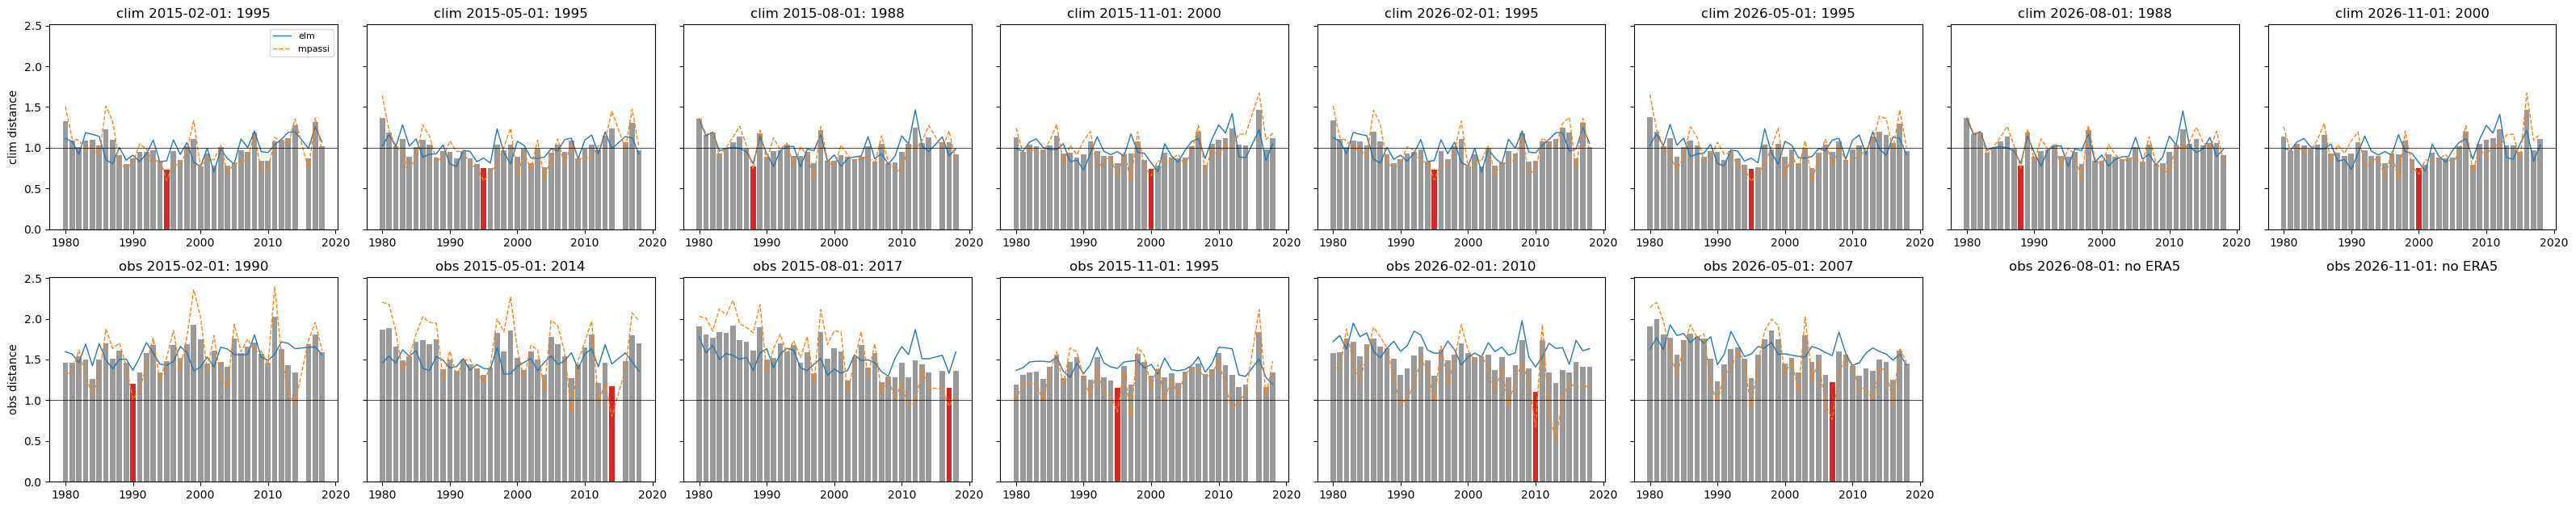

In [6]:
# Joint distance by year for each branch; the selected year is red.
fig, axes = plt.subplots(len(BRANCHES), len(TARGET_DATES), figsize=(4 * len(TARGET_DATES), 3.2 * len(BRANCHES)),
                         sharey=True, squeeze=False)
for r, branch in enumerate(BRANCHES):
    for c, date in enumerate(TARGET_DATES):
        ax = axes[r, c]
        if (branch, date) not in distances:
            ax.set_title(f"{branch} {date}: no ERA5")
            ax.axis("off")
            continue
        table = distances[(branch, date)]
        best = int(table["joint"].idxmin())
        years = table.index.to_numpy()
        ax.bar(years, table["joint"], color=["tab:red" if y == best else "0.6" for y in years])
        for comp, style in zip([c for c in COMPONENTS if c in table], ("-", "--", ":")):
            ax.plot(years, table[comp], style, lw=1, label=comp)
        ax.axhline(1, color="k", lw=0.5)
        ax.set_title(f"{branch} {date}: {best}")
    axes[r, 0].set_ylabel(f"{branch} distance")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

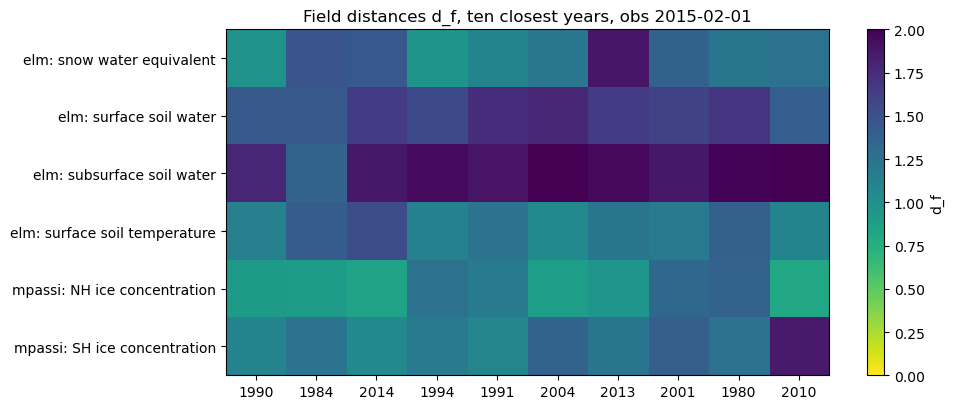

In [7]:
# Field distances of the ten closest years for one branch and date.
KEY = ("obs", TARGET_DATES[0])
table = distances[KEY].sort_values("joint").head(10)
fields = [c for c in table.columns if ": " in c]
fig, ax = plt.subplots(figsize=(10, 0.45 * len(fields) + 1.5))
im = ax.imshow(table[fields].T, aspect="auto", cmap="viridis_r", vmin=0, vmax=2)
ax.set_xticks(range(len(table)), table.index)
ax.set_yticks(range(len(fields)), fields)
ax.set_title(f"Field distances d_f, ten closest years, {KEY[0]} {KEY[1]}")
fig.colorbar(im, ax=ax, label="d_f")
fig.tight_layout()
plt.show()

## 3. Write the selected restarts

Copies each selected restart (unchanged) to
`OUT_ROOT/YYYYMMDD/<branch>/<prefix>.<stream>.<target date>.nc`, writes
`rpointer.lnd`, `rpointer.rof`, and `rpointer.ice`, and records the selection
and full distance table in `selection.json`. Set `WRITE_OUTPUT = True` to run.

In [8]:
if WRITE_OUTPUT:
    for key, plan in plans.items():
        write_selected_restarts(plan, selections[key], distances[key], mode=MODE, box=BOX,
                                component_weights=COMPONENT_WEIGHTS, overwrite=OVERWRITE)

rows = []
for (branch, date), plan in plans.items():
    for comp in COMPONENTS:
        year = selections[(branch, date)][comp]
        out, src = plan.output(comp), plan.source(comp, year)
        rows.append({"branch": branch, "target_date": date, "component": comp, "year": year,
                     "written": out.is_file(),
                     "same size as source": out.is_file() and out.stat().st_size == src.stat().st_size})
display(pd.DataFrame(rows))

,branch,target_date,component,year,written,same size as source
0,clim,2015-02-01,elm,1995,False,False
1,clim,2015-02-01,mosart,1995,False,False
2,clim,2015-02-01,mpassi,1995,False,False
3,clim,2015-05-01,elm,1995,False,False
4,clim,2015-05-01,mosart,1995,False,False
5,clim,2015-05-01,mpassi,1995,False,False
6,clim,2015-08-01,elm,1988,False,False
7,clim,2015-08-01,mosart,1988,False,False
8,clim,2015-08-01,mpassi,1988,False,False
9,clim,2015-11-01,elm,2000,False,False
